# M1 notebook · Quratulain
**Send by tonight 10 pm (Tue 20 Oct).** The team shows the result in the lab tomorrow (Wed 21 Oct).

## What this is about (30 seconds)
Tomorrow we show the instructor two things:
- a **data-quality report**: what is missing or wrong in our data, and what we decided to do about it;
- **EDA**: first numbers and charts about the data.

**Your part:** missing values, duplicates, inconsistent values, two EDA charts, and the data dictionary (a table that explains every column).

Two words used below:
- **Pull request** = your message to Ahtisham saying "please check my change". GitHub makes it for you when you follow the clicks.
- **Colab** = the website where you are reading this file.

## You have 2 jobs tonight. Do Job 1 first.
| | Job | Time |
|---|---|---|
| **Job 1** | Fix your notes file on GitHub | 30 min |
| **Job 2** | Run this notebook and send it | 1-2 hours |

Why Job 1 first: Ahtisham compared your notes file with the real data and found file names and numbers that do not match (they came from the Kaggle page, not from our data). If they stay, they end up in our report.

## Facts you can trust (checked by Ahtisham on the real data, 12 Oct; also in `DATA_MANIFEST.md`)
| File (inside the data folder) | Rows | Columns |
|---|---|---|
| `postings.csv` | 123,849 | 31 |
| `jobs/job_skills.csv` | 213,768 | 2 |
| `jobs/salaries.csv` | 40,785 | 8 |
| `jobs/benefits.csv` | 67,943 | 3 |
| `jobs/job_industries.csv` | 164,808 | 2 |
| `companies/companies.csv` | 24,473 | 10 |
| `companies/company_industries.csv` | 24,375 | 2 |
| `companies/company_specialities.csv` | 169,387 | 2 |
| `companies/employee_counts.csv` | 35,787 | 4 |
| `mappings/skills.csv` | 35 | 2 |
| `mappings/industries.csv` | 422 | 2 |

Other checked facts:
- 0 repeated `job_id`. `description` is empty in 7 rows.
- Pay is given in only 36,073 postings (29.1%).
- `skills_desc` is empty in about 98% of postings.
- The Kaggle page lists old file names (`job_postings.csv`, `job_details/`, `company_details/`). They are outdated: use the names above.

## JOB 1 · Fix your notes file (30 min)
File to fix: `quratulaain/linkedin_job_postings_data_mining.md` (already merged).

**Steps**
1. Open https://github.com/AHTISHAM327/ai-job-market-skill-miner -> click folder **quratulaain** -> click **linkedin_job_postings_data_mining.md** -> click the **pencil icon** (Edit this file).
2. Fix these things (the right answers are in the Facts table above):
   - [ ] Change `job_postings.csv` to `postings.csv`. Use the real file names from the Facts table everywhere. Delete the sentence "Some download versions also include extra files...".
   - [ ] Change "72,521 companies" to **24,473 companies**. `companies/companies.csv` has 24,473 rows and 10 columns. Use the exact row counts from the table for the other files too (for example benefits = 67,943 rows).
   - [ ] Any other number you did not check yourself: write "not checked" next to it.
   - [ ] Delete the generic tasks (regression, Apriori on benefits, predicting experience level). They are not our project. Write our 3 questions instead:
     1. Which skills appear together in data/AI jobs? (association rules, FP-Growth)
     2. What job families exist? (TF-IDF + k-means clustering)
     3. Can we predict a salary band? (decision tree / random forest)
3. Click **Commit changes...**, choose **Create a new branch for this commit and start a pull request**, click **Propose changes**, then **Create pull request**.
4. Write "fix sent" in the group. **Then start Job 2.**

## JOB 2 · Run this notebook and send it (1-2 hours)
1. This file is already open in Colab. Click **Runtime -> Run all**. When it asks about Google Drive, click **Connect to Google Drive** and **Allow**. The data is big: wait 5-10 minutes.
2. Scroll down and read every output. Each section has a line "What this shows" so you know what you are looking at.
3. Scroll to the **last cell** (section 8, "YOUR DECISIONS"). Double-click it and write your own decisions, each with a one-line reason. This part is your work, not a copy.
4. Send the file:
1. In Colab click **File -> Download -> Download .ipynb**.
2. Open https://github.com/AHTISHAM327/ai-job-market-skill-miner and click the folder **quratulaain**.
3. Click **Add file -> Upload files**, and drop the downloaded file in.
4. Under "Commit changes" choose **Create a new branch for this commit and start a pull request**. Click **Propose changes**, then **Create pull request**.
5. Write "notebook sent" in the group.

## If something goes wrong
- **Error `StopIteration` or "No such file or directory"** = the Drive shortcut is missing. Open Google Drive, click **Shared with me**, right-click the folder **AI Job Market Skill Miner**, choose **Organize -> Add shortcut -> My Drive**. Then click Runtime -> Run all again.
- **"Session crashed" or "out of memory"**: Runtime -> **Restart session**, then Run all again.
- **Any other red error**: take a screenshot and post it in the group. Do not guess.
- **You cannot finish by 10 pm**: tell the group **before 8 pm**. Ahtisham runs your notebook, and you explain it to him later.

## Three rules
1. **Every number you write comes from a cell you ran, or from the Facts table above.** If you did not check a number, write "not checked".
2. This code was written with AI help (Claude). Read every line before you run it: in the viva you must explain it and rerun it with a changed setting. Ahtisham adds the AI-use note to the report.
3. **The code only counts things. Deciding what to do about the numbers is your job.** Write your decisions, reasons and explanations yourself, in your own words. Nobody else (including AI) writes that part.

---
# The notebook starts here

## 1. Load

In [ ]:
# Shared loader (same cell for everyone). Needs the Drive shortcut of the shared folder in My Drive.
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
drive.mount("/content/drive")
SEED = 42
root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))
raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
print(sorted(files))
df = pd.read_csv(files["postings.csv"])
print("postings:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['benefits.csv', 'companies.csv', 'company_industries.csv', 'company_specialities.csv', 'employee_counts.csv', 'industries.csv', 'job_industries.csv', 'job_skills.csv', 'postings.csv', 'salaries.csv', 'skills.csv']
postings: (123849, 31)


## 2. Missing values (postings.csv)
Result: one table, column → % missing.

**What this shows:** how many cells are empty in each column. Empty cells cannot be used by a model, so for each column we must decide: drop it, fill it, or leave it.

In [ ]:
miss = pd.DataFrame({"n_missing": df.isna().sum(),
                     "pct_missing": (df.isna().mean() * 100).round(1)}).sort_values("pct_missing", ascending=False)
display(miss)
blank = df.select_dtypes("object").apply(lambda s: s.fillna("x").astype(str).str.strip().eq("").sum())
print("Blank strings that are not NaN:"); print(blank[blank > 0])

,n_missing,pct_missing
closed_time,122776,99.1
skills_desc,121410,98.0
med_salary,117569,94.9
remote_allowed,108603,87.7
applies,100529,81.2
min_salary,94056,75.9
max_salary,94056,75.9
currency,87776,70.9
compensation_type,87776,70.9
pay_period,87776,70.9


Blank strings that are not NaN:
Series([], dtype: int64)


## 3. Missing values and duplicate rows in the other 10 files

**What this shows:** the same check for the other 10 files, plus how many rows are exact copies.

In [ ]:
rows = []
for name, p in files.items():
    if name == "postings.csv":
        continue
    tb = pd.read_csv(p)
    rows.append({"file": name, "rows": len(tb), "cols": tb.shape[1],
                 "avg_pct_missing": round(float(tb.isna().mean().mean() * 100), 1),
                 "duplicate_rows": int(tb.duplicated().sum())})
display(pd.DataFrame(rows))

,file,rows,cols,avg_pct_missing,duplicate_rows
0,companies.csv,24473,10,1.3,0
1,company_industries.csv,24375,2,0.0,0
2,company_specialities.csv,169387,2,0.0,0
3,employee_counts.csv,35787,4,0.0,0
4,job_skills.csv,213768,2,0.0,0
5,job_industries.csv,164808,2,0.0,0
6,benefits.csv,67943,3,0.0,0
7,salaries.csv,40785,8,14.6,0
8,industries.csv,422,2,4.0,0
9,skills.csv,35,2,0.0,0


## 4. Duplicates (postings.csv)

**What this shows:** how many postings appear more than once (the same job posted again). Repeats would count the same skills twice, so we decide a rule to remove them.

In [ ]:
key = ["title", "company_id", "description"]
dup = {"repeated job_id": int(df["job_id"].duplicated().sum()),
       "fully identical rows": int(df.duplicated().sum()),
       "same title + company + description": int(df.duplicated(subset=key).sum()),
       "same title + company + location": int(df.duplicated(subset=["title", "company_id", "location"]).sum())}
display(pd.Series(dup, name="count"))
before = len(df)
df_nodup = df.drop_duplicates(subset=key, keep="first")
print("If we drop rows with the same title + company + description (keep first), the rows go:", before, "->", len(df_nodup),
      "| removed:", before - len(df_nodup))

,count
repeated job_id,0
fully identical rows,0
same title + company + description,12650
same title + company + location,8434


If we drop rows with the same title + company + description (keep first), the rows go: 123849 -> 111199 | removed: 12650


## 5. Inconsistent values

**What this shows:** the different values written in each column. If the same thing is written two ways (for example 'Full-time' and 'FULL_TIME'), we must write a rule that makes them one.

In [ ]:
for c in ["formatted_work_type", "work_type", "formatted_experience_level", "remote_allowed",
          "pay_period", "currency", "compensation_type", "sponsored", "application_type"]:
    print("\n==", c); print(df[c].value_counts(dropna=False).head(12))
print("\nwork_type vs formatted_work_type:"); display(pd.crosstab(df["work_type"], df["formatted_work_type"]))
print("min_salary > max_salary:", int((df["min_salary"] > df["max_salary"]).sum()))


== formatted_work_type
formatted_work_type
Full-time     98814
Contract      12117
Part-time      9696
Temporary      1190
Internship      983
Volunteer       562
Other           487
Name: count, dtype: int64

== work_type
work_type
FULL_TIME     98814
CONTRACT      12117
PART_TIME      9696
TEMPORARY      1190
INTERNSHIP      983
VOLUNTEER       562
OTHER           487
Name: count, dtype: int64

== formatted_experience_level
formatted_experience_level
Mid-Senior level    41489
Entry level         36708
NaN                 29409
Associate            9826
Director             3746
Internship           1449
Executive            1222
Name: count, dtype: int64

== remote_allowed
remote_allowed
NaN    108603
1.0     15246
Name: count, dtype: int64

== pay_period
pay_period
NaN         87776
YEARLY      20628
HOURLY      14741
MONTHLY       518
WEEKLY        177
BIWEEKLY        9
Name: count, dtype: int64

== currency
currency
NaN    87776
USD    36058
EUR        6
CAD        3
BBD        2

formatted_work_type,Contract,Full-time,Internship,Other,Part-time,Temporary,Volunteer
work_type,,,,,,,
CONTRACT,12117,0,0,0,0,0,0
FULL_TIME,0,98814,0,0,0,0,0
INTERNSHIP,0,0,983,0,0,0,0
OTHER,0,0,0,487,0,0,0
PART_TIME,0,0,0,0,9696,0,0
TEMPORARY,0,0,0,0,0,1190,0
VOLUNTEER,0,0,0,0,0,0,562


min_salary > max_salary: 0


In [ ]:
tt = df["title"].fillna("")
print("titles with leading/trailing spaces:", int((tt != tt.str.strip()).sum()))
print("titles with double spaces:", int(tt.str.contains(r"\s{2,}").sum()))
print("unique titles raw vs lower-cased+stripped:", tt.nunique(), "vs", tt.str.lower().str.strip().nunique())
loc = df["location"].fillna("")
ok = loc.str.contains(r",\s*[A-Z]{2}$")
print("locations without a comma:", int((~loc.str.contains(",")).sum()))
print("locations ending in a 2-letter state code:", int(ok.sum()), "of", len(loc))
print(loc[~ok].value_counts().head(15))

titles with leading/trailing spaces: 1977
titles with double spaces: 450
unique titles raw vs lower-cased+stripped: 72521 vs 71580
locations without a comma: 13365
locations ending in a 2-letter state code: 105090 of 123849
location
United States                      8125
New York City Metropolitan Area     837
New York, United States             587
California, United States           484
San Francisco Bay Area              318
Dallas-Fort Worth Metroplex         315
Texas, United States                299
Los Angeles Metropolitan Area       277
Washington DC-Baltimore Area        269
Atlanta Metropolitan Area           238
Florida, United States              237
Austin, Texas Metropolitan Area     234
Greater Houston                     212
New Jersey, United States           206
North Carolina, United States       199
Name: count, dtype: int64


## 6. EDA charts

**What this shows:** the two most basic pictures of our data: how many postings per seniority level and per work type.

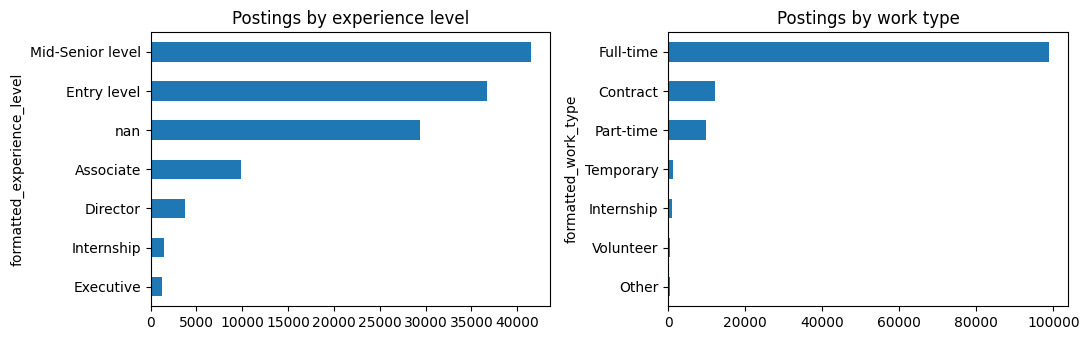

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["formatted_experience_level"].value_counts(dropna=False).sort_values().plot.barh(ax=ax[0], title="Postings by experience level")
df["formatted_work_type"].value_counts(dropna=False).sort_values().plot.barh(ax=ax[1], title="Postings by work type")
plt.tight_layout(); plt.show()

## 7. Data dictionary (31 columns)

**What this shows:** one row per column: its type, how empty it is, what it means, and whether we keep it. The code fills type and % missing. **You write `meaning` and `keep` yourself** in the code cell below (the two dictionaries), using the Kaggle page or `rija/dataset_notes.md` section 3, checked against the table. Ahtisham copies the printed table into the report.

In [ ]:
dd = pd.DataFrame({"column": df.columns, "type": df.dtypes.astype(str).values,
                   "pct_missing": (df.isna().mean() * 100).round(1).values, "n_unique": df.nunique().values})
# YOUR JOB: fill these two dictionaries for all 31 columns, in your own words.
# Meanings: Kaggle page or rija/dataset_notes.md (section 3), checked against the table printed below.
meaning = {}   # example: "job_id": "unique ID of the posting"
keep = {}      # example: "job_id": "keep"   or   "zip_code": "drop (mostly empty)"
dd["meaning"] = dd["column"].map(meaning).fillna("")
dd["keep_or_drop"] = dd["column"].map(keep).fillna("")
display(dd)
print("columns still without a meaning:", int((dd["meaning"] == "").sum()))
try:
    print(dd.to_markdown(index=False))
except Exception:
    print(dd.to_string(index=False))

,column,type,pct_missing,n_unique,meaning,keep_or_drop
0,job_id,int64,0.0,123849,,
1,company_name,object,1.4,24428,,
2,title,object,0.0,72521,,
3,description,object,0.0,107827,,
4,max_salary,float64,75.9,5321,,
5,pay_period,object,70.9,5,,
6,location,object,0.0,8526,,
7,company_id,float64,1.4,24474,,
8,views,float64,1.4,684,,
9,med_salary,float64,94.9,1417,,


columns still without a meaning: 31
| column                     | type    |   pct_missing |   n_unique | meaning   | keep_or_drop   |
|:---------------------------|:--------|--------------:|-----------:|:----------|:---------------|
| job_id                     | int64   |           0   |     123849 |           |                |
| company_name               | object  |           1.4 |      24428 |           |                |
| title                      | object  |           0   |      72521 |           |                |
| description                | object  |           0   |     107827 |           |                |
| max_salary                 | float64 |          75.9 |       5321 |           |                |
| pay_period                 | object  |          70.9 |          5 |           |                |
| location                   | object  |           0   |       8526 |           |                |
| company_id                 | float64 |           1.4 |      24474 |    

## 8. YOUR DECISIONS (double-click and write; every decision needs a one-line reason, in your own words)

**Missing values** - for each column that matters (look at section 2):

| Column | % missing | Decision (drop / fill / leave) | Reason |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

**Duplicates** - your numbers from section 4, the rule you chose, and why:

**Cleaning rules** (from section 5) - numbered, each with a before -> after example:

1.
2.
3.